# Checkpoint 5: Tích Hợp Đồng Thời Class Weights và Focal Loss (Weighted Focal Loss) & Nghiên Cứu Bóc Tách Thành Phần (Ablation Study)

Nghiên cứu: Nâng cao hiệu năng mô hình phát hiện phát ngôn thù ghét trên mạng xã hội tiếng Việt (ViHSD).

Mục tiêu kỹ thuật của Checkpoint 5:
1. Tổng hợp đồng thời hai cơ chế giải quyết mất cân bằng lớp đã kiểm chứng độc lập ở Checkpoint 3 và Checkpoint 4:
   - **Cân bằng phân bố lớp tĩnh (Class Weight $\alpha_c$):** Bù đắp sự chênh lệch số lượng mẫu giữa lớp đa số CLEAN (~82.7%) và hai lớp thiểu số OFFENSIVE (~6.7%), HATE (~10.6%).
   - **Điều chế mẫu khó động (Focal Modulating Factor $(1 - p_t)^\gamma$):** Tự động triệt tiêu gradient từ các mẫu dễ phân loại ($p_t \to 1$) và tập trung vào các mẫu nằm sát ranh giới quyết định phức tạp.
2. Công thức toán học của hàm mất mát kết hợp (Weighted Focal Loss):
   $$\mathcal{L}_{WFL}(p_t) = -\alpha_{y_i} (1 - p_{i, y_i})^\gamma \log(p_{i, y_i})$$
   Trong đó $\gamma = 2.0$ và vector trọng số tĩnh $\alpha$ được khởi tạo từ phương pháp nghịch đảo tần suất lớp (ICF).
3. Phân tích cơ chế tác động hiệp đồng (Synergistic Effect):
   - Mẫu CLEAN dễ ($p_t \approx 0.95$): Trọng số tĩnh $\alpha_0 \approx 0.40$ kết hợp với hệ số điều chế $(1 - 0.95)^2 = 0.0025$ triệt tiêu gần như hoàn toàn gradient, ngăn ngừa hiện tượng lấn át gradient từ lớp đa số.
   - Mẫu HATE khó ($p_t \approx 0.20$): Trọng số tĩnh $\alpha_2 \approx 3.14$ kết hợp hệ số điều chế $(1 - 0.20)^2 = 0.64$ duy trì mức phạt gradient cao, buộc mô hình tối ưu mạnh mẽ vào các mẫu thù ghét tinh vi.
4. Thực hiện nghiên cứu bóc tách thành phần toàn diện (Comprehensive Ablation Study): Đối chiếu tường minh 4 biến thể hàm mất mát (Standard CE, Focal Loss, Weighted CE, Weighted Focal Loss) cùng trên tập kiểm tra chuẩn `test.csv`.
5. Phân tích lỗi định tính (Qualitative Error Analysis) trên ma trận nhầm lẫn: Phân loại 3 dạng lỗi điển hình (từ ngữ nhạy cảm đùa vui, chửi thề bộc phát vs thù ghét có mục tiêu, và phát ngôn thù ghét ẩn ý dạng châm biếm/mỉa mai).

Ghi chú: Toàn bộ mã nguồn được thiết kế độc lập 100% (Self-Contained) trên Google Colab, không phụ thuộc vào các tệp module .py bên ngoài.

In [1]:
import os
import sys

# Thiết lập môi trường làm việc và kết nối Google Drive trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = '/content/drive/MyDrive/NLP_PhoBert_ViHSD'
except ImportError:
    project_dir = os.path.abspath('..')

checkpoints_dir = os.path.join(project_dir, 'checkpoints', 'checkpoint05')
outputs_dir = os.path.join(project_dir, 'outputs', 'checkpoint05')

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)

print(f'Thư mục dự án: {project_dir}')
print(f'Thư mục lưu checkpoint: {checkpoints_dir}')
print(f'Thư mục lưu kết quả: {outputs_dir}')

Mounted at /content/drive
Thư mục dự án: /content/drive/MyDrive/NLP_PhoBert_ViHSD
Thư mục lưu checkpoint: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint05
Thư mục lưu kết quả: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05


In [2]:
# Cài đặt các thư viện cần thiết trên môi trường Google Colab
!pip install -q pyvi transformers accelerate scikit-learn seaborn matplotlib pandas numpy torch

In [3]:
# Thiết lập hạt giống ngẫu nhiên cố định để đảm bảo tính tái lập thực nghiệm
random_seed = 42

import os
import random
import numpy as np
import torch

random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f'Hạt giống ngẫu nhiên đã được cố định: {random_seed}')
print(f'Thiết bị tính toán: {"CUDA (GPU)" if torch.cuda.is_available() else "CPU"}')
if torch.cuda.is_available():
    print(f'Tên GPU: {torch.cuda.get_device_name(0)}')
    print(f'Dung lượng VRAM khả dụng: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')

Hạt giống ngẫu nhiên đã được cố định: 42
Thiết bị tính toán: CUDA (GPU)
Tên GPU: Tesla T4
Dung lượng VRAM khả dụng: 14.56 GB


## 1. Nạp Tập Dữ Liệu Thô và Kiểm Tra Trước Xử Lý (Pre-pipeline Verification)

Kiểm tra tính toàn vẹn của ba tập dữ liệu chuẩn: `train.csv` (24,048 mẫu), `dev.csv` (2,672 mẫu) và `test.csv` (6,680 mẫu). Đảm bảo số lượng mẫu khớp tuyệt đối với nghiên cứu cơ sở của Luu et al. (2021) và phân tích sự phân bổ mất cân bằng nghiêm trọng giữa các nhãn.

In [4]:
# Cấu hình đường dẫn tập dữ liệu
data_dir = 'data' if os.path.exists('data/train.csv') else os.path.join(project_dir, 'data')
train_path = os.path.join(data_dir, 'train.csv')
dev_path = os.path.join(data_dir, 'dev.csv')
test_path = os.path.join(data_dir, 'test.csv')

import pandas as pd

print(f'Đọc tập Train từ: {train_path}')
print(f'Đọc tập Dev từ:   {dev_path}')
print(f'Đọc tập Test từ:  {test_path}')

train_raw = pd.read_csv(train_path)
dev_raw = pd.read_csv(dev_path)
test_raw = pd.read_csv(test_path)

# Kiểm tra toàn vẹn số lượng mẫu và giá trị thiếu trước khi đưa vào pipeline
assert len(train_raw) == 24048, f'Số lượng mẫu train không khớp: {len(train_raw)}'
assert len(dev_raw) == 2672, f'Số lượng mẫu dev không khớp: {len(dev_raw)}'
assert len(test_raw) == 6680, f'Số lượng mẫu test không khớp: {len(test_raw)}'

print('Kiểm tra tập dữ liệu thô trước xử lý:')
print(f'- Train: {len(train_raw)} mẫu, giá trị thiếu free_text: {train_raw["free_text"].isna().sum()}')
print(f'- Dev:   {len(dev_raw)} mẫu, giá trị thiếu free_text: {dev_raw["free_text"].isna().sum()}')
print(f'- Test:  {len(test_raw)} mẫu, giá trị thiếu free_text: {test_raw["free_text"].isna().sum()}')

# Thống kê phân bổ nhãn trên tập huấn luyện
train_dist = train_raw['label_id'].value_counts().sort_index()
print('\nPhân bổ nhãn trên tập huấn luyện:')
class_labels = {0: 'CLEAN', 1: 'OFFENSIVE', 2: 'HATE'}
for label_id, count in train_dist.items():
    pct = (count / len(train_raw)) * 100
    print(f'  Lớp {label_id} ({class_labels.get(label_id, "UNKNOWN")}): {count:5d} mẫu ({pct:5.2f}%)')

Đọc tập Train từ: data/train.csv
Đọc tập Dev từ:   data/dev.csv
Đọc tập Test từ:  data/test.csv
Kiểm tra tập dữ liệu thô trước xử lý:
- Train: 24048 mẫu, giá trị thiếu free_text: 2
- Dev:   2672 mẫu, giá trị thiếu free_text: 0
- Test:  6680 mẫu, giá trị thiếu free_text: 0

Phân bổ nhãn trên tập huấn luyện:
  Lớp 0 (CLEAN): 19886 mẫu (82.69%)
  Lớp 1 (OFFENSIVE):  1606 mẫu ( 6.68%)
  Lớp 2 (HATE):  2556 mẫu (10.63%)


## 2. Định Nghĩa Trực Tiếp Lớp Tiền Xử Lý ViHSDPreprocessor

Tái sử dụng quy trình tiền xử lý chuẩn hóa đã kiểm chứng ở Checkpoint 1:
1. Làm sạch URL, Email, thẻ HTML và chuẩn hóa khoảng trắng thừa.
2. Xử lý biểu tượng cảm xúc (Emoji) 2 pha: đệm khoảng trắng bảo vệ từ tố và ánh xạ sang từ vựng tiếng Việt tương ứng.
3. Chuẩn hóa teencode, từ lóng và biến thể né kiểm duyệt bằng ranh giới từ (Word Boundary Protection).
4. Thu gọn ký tự lặp kéo dài (Lengthening Reduction) về 1 ký tự duy nhất.
5. Phân đoạn từ tiếng Việt tự động bằng thư viện `PyVi` theo chuẩn đầu vào PhoBERT.
6. Bảo tồn toàn bộ đại từ nhân xưng (`mày`, `tao`, `nó`, `thằng`, `con`) và từ phủ định (`không`, `chẳng`, `chả`).

In [5]:
import os
import re
import pandas as pd
import numpy as np

try:
    from pyvi import ViTokenizer
except ImportError:
    ViTokenizer = None


class ViHSDPreprocessor:
    """Bộ tiền xử lý và chuẩn hóa văn bản cho bài toán phát hiện phát ngôn thù ghét (ViHSD).

    Quy trình xử lý bao gồm:
    1. Làm sạch URL, Email, thẻ HTML và chuẩn hóa khoảng trắng.
    2. Bảo tồn và ánh xạ sắc thái cảm xúc (Emoji) qua quy trình 2 pha dựa vào từ điển bên ngoài.
    3. Chuẩn hóa teencode, tiếng lóng và biến thể né kiểm duyệt qua từ điển bên ngoài.
    4. Thu gọn ký tự lặp kéo dài (Lengthening Reduction).
    5. Bảo tồn nguyên vẹn từ dừng, đại từ nhân xưng và từ phủ định.
    6. Phân đoạn từ tiếng Việt sử dụng PyVi.
    """

    # Khởi tạo đối tượng tiền xử lý với các đường dẫn từ điển teencode và emoji
    def __init__(self, teencode_path='data/teencode.csv', emoji_path='data/emojis.csv'):
        self.teencode_dict = self.load_teencode(teencode_path)
        self.emoji_dict = self.load_emoji_mapping(emoji_path)
        self._init_regex_patterns()

    # Biên dịch trước toàn bộ biểu thức chính quy nhằm tối ưu tốc độ xử lý trên tập dữ liệu lớn
    def _init_regex_patterns(self):
        self.url_pattern = re.compile(r'https?://\S+|www\.\S+', re.IGNORECASE)
        self.email_pattern = re.compile(r'\S+@\S+', re.IGNORECASE)
        self.html_pattern = re.compile(r'<.*?>')
        self.whitespace_pattern = re.compile(r'\s+')

        # Nhận diện ký tự chữ cái lặp lại từ 3 lần trở lên bao gồm cả bảng chữ cái tiếng Việt
        self.lengthening_pattern = re.compile(
            r'([a-zA-ZàáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵđĐ])\1{2,}',
            re.IGNORECASE,
        )

        # Biểu thức đệm khoảng trắng bao quanh emoji để ngăn lỗi dính từ khi tách từ bằng PyVi
        self.emoji_padding_pattern = re.compile(
            r'(\s*)([\U00010000-\U0010ffff\u2600-\u27ff])(\s*)'
        )

        # Mẫu khớp từ điển emoji theo thứ tự độ dài giảm dần
        sorted_emojis = sorted(self.emoji_dict.keys(), key=len, reverse=True)
        self.emoji_replace_pattern = re.compile(
            '|'.join(re.escape(k) for k in sorted_emojis)
        )

        # Mẫu khớp teencode kết hợp biên giới từ để tránh thay thế nhầm từ tố hợp lệ
        sorted_teencode = sorted(self.teencode_dict.keys(), key=len, reverse=True)
        teencode_patterns = []
        for k in sorted_teencode:
            escaped = re.escape(k)
            left = r'(?<!\w)' if re.match(r'^\w', k) else ''
            right = r'(?!\w)' if re.search(r'\w$', k) else ''
            teencode_patterns.append(f'{left}{escaped}{right}')
        self.teencode_pattern = re.compile(
            '|'.join(teencode_patterns), re.IGNORECASE
        )

    # Đọc từ điển teencode và từ lóng từ tệp CSV thành từ điển ánh xạ
    def load_teencode(self, path):
        df = pd.read_csv(path)
        return dict(
            zip(
                df['teencode'].astype(str).str.strip().str.lower(),
                df['replacement'].astype(str).str.strip().str.lower(),
            )
        )

    # Đọc bảng ánh xạ biểu tượng cảm xúc (emoji) từ tệp CSV thành từ điển thay thế
    def load_emoji_mapping(self, path):
        df = pd.read_csv(path)
        return dict(
            zip(
                df['emoji'].astype(str).str.strip(),
                df['replacement'].astype(str).str.strip(),
            )
        )

    # Loại bỏ đường dẫn URL, địa chỉ email, thẻ HTML và khoảng trắng thừa
    def clean_special_characters(self, text):
        text = self.url_pattern.sub(' ', text)
        text = self.email_pattern.sub(' ', text)
        text = self.html_pattern.sub(' ', text)
        return self.whitespace_pattern.sub(' ', text).strip()

    # Xử lý emoji 2 pha: đệm khoảng trắng bảo vệ từ tố rồi ánh xạ ngữ nghĩa sang PhoBERT
    def pad_and_map_emojis(self, text):
        text = self.emoji_padding_pattern.sub(r' \2 ', text)
        text = self.emoji_replace_pattern.sub(
            lambda m: f' {self.emoji_dict[m.group(0)]} ', text
        )
        return self.whitespace_pattern.sub(' ', text).strip()

    # Chuẩn hóa từ viết tắt và tiếng lóng dựa trên biên giới từ
    def normalize_teencode(self, text):
        return self.teencode_pattern.sub(
            lambda m: self.teencode_dict.get(m.group(0).lower(), m.group(0)), text
        )

    # Thu gọn các ký tự chữ cái lặp lại liên tiếp từ 3 lần trở lên về 1 ký tự duy nhất
    def reduce_lengthening(self, text):
        return self.lengthening_pattern.sub(r'\1', text)

    # Phân đoạn từ tiếng Việt tự động bằng thư viện PyVi theo quy chuẩn PhoBERT
    def segment_words(self, text):
        if ViTokenizer is None:
            raise ImportError(
                'Thư viện pyvi chưa được cài đặt. Vui lòng cài đặt qua lệnh: pip install pyvi'
            )
        return ViTokenizer.tokenize(text)

    # Thực hiện quy trình tiền xử lý hoàn chỉnh cho một đoạn văn bản theo đúng thứ tự logic
    def transform_text(self, text, lowercased=False):
        if not isinstance(text, str):
            text = str(text) if text is not None else ''

        if not text.strip():
            return ''

        # Thực hiện tuần tự: Làm sạch -> Emoji -> Teencode -> Thu gọn ký tự -> Tách từ PyVi
        text = self.clean_special_characters(text)
        text = self.pad_and_map_emojis(text)
        text = self.normalize_teencode(text)
        text = self.reduce_lengthening(text)

        # Bảo tồn toàn bộ đại từ nhân xưng và từ phủ định (tuyệt đối không lọc từ dừng)
        if text.strip():
            text = self.segment_words(text)

        if lowercased:
            text = text.lower()

        return self.whitespace_pattern.sub(' ', text).strip()

    # Áp dụng chuẩn hóa trên toàn bộ DataFrame, loại bỏ dòng rỗng/thiếu và trả về mảng đặc trưng X và nhãn y
    def transform_dataset(self, df, text_col='free_text', label_col='label_id', lowercased=False):
        df_clean = df.dropna(subset=[text_col, label_col]).copy()
        df_clean[label_col] = df_clean[label_col].astype(int)

        transformed_texts = []
        valid_indices = []

        for idx, row in df_clean.iterrows():
            cleaned_text = self.transform_text(row[text_col], lowercased=lowercased)
            if cleaned_text:
                transformed_texts.append(cleaned_text)
                valid_indices.append(idx)

        filtered_df = df_clean.loc[valid_indices].copy()
        X = transformed_texts
        y = filtered_df[label_col].to_numpy()

        return X, y

## 3. Khởi Tạo Bộ Tiền Xử Lý và Chuẩn Hóa Dữ Liệu

Áp dụng quy trình tiền xử lý đồng bộ trên cả ba tập `train.csv`, `dev.csv` và `test.csv`. Kiểm tra tính toàn vẹn (Assertion Checks) sau khi làm sạch nhằm loại bỏ hoàn toàn các chuỗi rỗng và đảm bảo tính nhất quán về kích thước và nhãn phân loại.

In [6]:
# Cấu hình đường dẫn từ điển chuẩn hóa
teencode_path = os.path.join(data_dir, 'teencode.csv')
emoji_path = os.path.join(data_dir, 'emojis.csv')

print(f'Nạp từ điển teencode từ: {teencode_path}')
print(f'Nạp từ điển emoji từ:    {emoji_path}')

# Khởi tạo bộ tiền xử lý với từ điển ngoài
preprocessor = ViHSDPreprocessor(teencode_path=teencode_path, emoji_path=emoji_path)

# Thực thi tiền xử lý trên toàn bộ tập dữ liệu
text_column = 'free_text'
label_column = 'label_id'
preserve_casing = False

train_X, train_y = preprocessor.transform_dataset(
    train_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)
dev_X, dev_y = preprocessor.transform_dataset(
    dev_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)
test_X, test_y = preprocessor.transform_dataset(
    test_raw, text_col=text_column, label_col=label_column, lowercased=preserve_casing
)

# Kiểm tra tính toàn vẹn sau xử lý (Post-pipeline Verification)
assert len(train_X) == len(train_y), 'Số lượng đặc trưng và nhãn train không khớp'
assert len(dev_X) == len(dev_y), 'Số lượng đặc trưng và nhãn dev không khớp'
assert len(test_X) == len(test_y), 'Số lượng đặc trưng và nhãn test không khớp'
assert sum(len(x.strip()) == 0 for x in train_X) == 0, 'Tồn tại chuỗi rỗng trong train_X'
assert set(np.unique(train_y)).issubset({0, 1, 2}), 'Tồn tại nhãn không hợp lệ trong train_y'

print('Kết quả tiền xử lý dữ liệu thành công:')
print(f'- Tập Train hợp lệ: {len(train_X)} / {len(train_raw)}')
print(f'- Tập Dev hợp lệ:   {len(dev_X)} / {len(dev_raw)}')
print(f'- Tập Test hợp lệ:  {len(test_X)} / {len(test_raw)}')

Nạp từ điển teencode từ: data/teencode.csv
Nạp từ điển emoji từ:    data/emojis.csv
Kết quả tiền xử lý dữ liệu thành công:
- Tập Train hợp lệ: 24046 / 24048
- Tập Dev hợp lệ:   2671 / 2672
- Tập Test hợp lệ:  6680 / 6680


## 4. Định Nghĩa Lớp BuildDataset và Mã Hóa Với Độ Dài Mở Rộng (max_length = 256)

Kế thừa cấu hình tokenization tối ưu từ Checkpoint 2:
- Mở rộng độ dài chuỗi tối đa `max_length = 256` token, bao phủ trọn vẹn ngữ cảnh bình luận mạng xã hội mà không bị cắt cụt.
- Sử dụng `AutoTokenizer.from_pretrained('vinai/phobert-base', use_fast=False)` tương thích với thuật toán FastBPE của PhoBERT.
- Đóng gói dữ liệu vào lớp `BuildDataset` tương thích với PyTorch và Hugging Face Trainer.

In [7]:
# Cấu hình tham số mã hóa chuỗi mở rộng cho Checkpoint 5
pretrained_model_name = 'vinai/phobert-base'
max_seq_length = 256

import torch
from transformers import AutoTokenizer


class BuildDataset(torch.utils.data.Dataset):
    """Lớp quản lý và đóng gói tập dữ liệu tương thích với Hugging Face Trainer và mô hình PhoBERT."""

    # Khởi tạo đối tượng tập dữ liệu với đặc trưng token hóa và mảng nhãn tương ứng
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    # Trích xuất mẫu dữ liệu tại chỉ mục xác định và đóng gói thành PyTorch Tensor
    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    # Trả về tổng số lượng mẫu quan sát có trong tập dữ liệu
    def __len__(self):
        return len(self.labels)


print(f'Khởi tạo Tokenizer: {pretrained_model_name} (use_fast=False, max_length={max_seq_length})')
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name, use_fast=False)

train_encodings = tokenizer(train_X, truncation=True, padding=True, max_length=max_seq_length)
dev_encodings = tokenizer(dev_X, truncation=True, padding=True, max_length=max_seq_length)
test_encodings = tokenizer(test_X, truncation=True, padding=True, max_length=max_seq_length)

train_dataset = BuildDataset(train_encodings, train_y)
dev_dataset = BuildDataset(dev_encodings, dev_y)
test_dataset = BuildDataset(test_encodings, test_y)

print(f'Kích thước tập train sau mã hóa: {len(train_dataset)}')
print(f'Kích thước tập dev sau mã hóa:   {len(dev_dataset)}')
print(f'Kích thước tập test sau mã hóa:  {len(test_dataset)}')

Khởi tạo Tokenizer: vinai/phobert-base (use_fast=False, max_length=256)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Kích thước tập train sau mã hóa: 24046
Kích thước tập dev sau mã hóa:   2671
Kích thước tập test sau mã hóa:  6680


## 5. Định Nghĩa Hàm Mất Mát Kết Hợp Weighted Focal Loss và Lớp CombinedLossTrainer

Định nghĩa hàm mất mát kết hợp giải quyết đồng thời hai khía cạnh của mất cân bằng dữ liệu:
$$\mathcal{L}_{WFL}(p_t) = -\alpha_{y_i} (1 - p_{i, y_i})^\gamma \log(p_{i, y_i})$$
Trong đó:
- $\alpha_{y_i}$ là trọng số phạt phân bố lớp tĩnh tính từ phương pháp Nghịch đảo tần suất lớp (ICF):
  $$\alpha_c = \frac{N}{K \cdot N_c}$$
- $(1 - p_{i, y_i})^\gamma$ là hệ số điều chế mẫu khó động với $\gamma = 2.0$.

Sự kết hợp này đảm bảo tính ổn định số học cao thông qua việc tính toán `ce_loss = F.cross_entropy(logits, targets, reduction='none')` và $p_t = \exp(-\text{ce\_loss})$.

In [8]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import Trainer


# Tính toán vector trọng số lớp ICF từ tập train_y
def compute_icf_weights(labels):
    """Tính toán vector trọng số lớp ICF chuẩn Scikit-learn."""
    labels = np.asarray(labels, dtype=int)
    total_samples = len(labels)
    classes, counts = np.unique(labels, return_counts=True)
    num_classes = len(classes)
    w_icf = total_samples / (num_classes * counts.astype(np.float64))
    return torch.tensor(w_icf, dtype=torch.float32)


class_weights_icf = compute_icf_weights(train_y)
print(f'Vector trọng số tĩnh alpha (ICF): {[round(float(v), 4) for v in class_weights_icf]}')


# Định nghĩa lớp hàm mất mát Weighted Focal Loss kết hợp trọng số tĩnh và điều chế động
class WeightedFocalLoss(nn.Module):
    """Hàm mất mát Weighted Focal Loss kết hợp trọng số lớp tĩnh alpha và hệ số điều chế gamma.

    Công thức:
        WFL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)
    """

    # Khởi tạo hàm mất mát với hệ số alpha, tham số tập trung gamma và reduction
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.reduction = reduction

    # Lan truyền xuôi tính toán tổn thất kết hợp ổn định số học
    def forward(self, logits, targets):
        """Tính toán tổn thất Weighted Focal Loss trên mini-batch."""
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        modulating_factor = (1.0 - pt) ** self.gamma
        focal_loss = modulating_factor * ce_loss

        if self.alpha is not None:
            if isinstance(self.alpha, torch.Tensor):
                alpha_t = self.alpha.to(logits.device)[targets]
                focal_loss = alpha_t * focal_loss
            else:
                focal_loss = self.alpha * focal_loss

        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        return focal_loss


# Lớp Trainer tùy biến tích hợp Weighted Focal Loss cho Hugging Face Trainer
class CombinedLossTrainer(Trainer):
    """Lớp Trainer áp dụng hàm mất mát Weighted Focal Loss."""

    # Khởi tạo Trainer với trọng số lớp alpha và tham số gamma
    def __init__(self, *args, class_weights=None, focal_gamma=2.0, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
        self.focal_gamma = focal_gamma
        self.loss_fn = WeightedFocalLoss(
            alpha=class_weights, gamma=focal_gamma, reduction='mean'
        )

    # Ghi đè phương thức tính toán tổn thất áp dụng Weighted Focal Loss
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        """Tính toán tổn thất trên mini-batch sử dụng Weighted Focal Loss."""
        labels = inputs.get('labels')
        outputs = model(**inputs)
        logits = outputs.get('logits')

        loss = self.loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss


# Kiểm tra tính ổn định số học của hàm mất mát kết hợp
dummy_logits = torch.tensor([[2.5, 0.2, 0.1], [0.1, 2.8, 0.3]], dtype=torch.float32)
dummy_targets = torch.tensor([0, 1], dtype=torch.long)
wfl_val = WeightedFocalLoss(alpha=class_weights_icf, gamma=2.0)(dummy_logits, dummy_targets)
assert not torch.isnan(wfl_val) and not torch.isinf(wfl_val), 'Lỗi số học trong WeightedFocalLoss'
print(f'Kiểm tra WeightedFocalLoss thành công, giá trị tổn thất: {wfl_val.item():.4f}')

Vector trọng số tĩnh alpha (ICF): [0.4031, 4.994, 3.1359]
Kiểm tra WeightedFocalLoss thành công, giá trị tổn thất: 0.0068


## 6. Cấu Hình Siêu Tham Số, Phân Tầng Tốc Độ Học và Thiết Lập CombinedLossTrainer

Cấu hình tối ưu hóa đồng nhất để đánh giá chính xác tác động của hàm mất mát kết hợp:
- Tốc độ học phân tầng: $\text{lr}_{\text{backbone}} = 2 \times 10^{-5}$ cho PhoBERT và $\text{lr}_{\text{head}} = 1 \times 10^{-4}$ cho Classification Head.
- Tích lũy gradient: `per_device_train_batch_size = 16`, `gradient_accumulation_steps = 2` (kích thước batch hiệu dụng = 32).
- Lịch trình học: Cosine Annealing Scheduler kèm 10% Warmup tuyến tính qua 8 epochs.
- Chiến lược đánh giá và lưu checkpoint: `eval_strategy='epoch'`, `save_strategy='epoch'`, `load_best_model_at_end=True`, `metric_for_best_model='eval_macro_f1'`.
- Early Stopping: dừng sớm nếu chỉ số `eval_macro_f1` không cải thiện sau 2 epoch liên tiếp (`patience = 2`).

In [9]:
# Thiết lập siêu tham số tối ưu hóa cho Checkpoint 5
num_labels = 3
num_epochs = 8
train_batch_size = 16
eval_batch_size = 16
gradient_accumulation_steps = 2
backbone_lr = 2e-5
head_lr = 1e-4
warmup_ratio = 0.1
weight_decay = 0.01
early_stopping_patience = 2
focal_gamma = 1.0

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import (
    AutoModelForSequenceClassification,
    EarlyStoppingCallback,
    TrainingArguments,
)


# Hàm callback tính toán các chỉ số Accuracy, Precision, Recall và F1 trong quá trình huấn luyện
def compute_metrics_eval(eval_pred):
    """Hàm callback đánh giá tích hợp trực tiếp vào Hugging Face Trainer."""
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=-1)

    acc = accuracy_score(labels, preds)
    macro_p = precision_score(labels, preds, average='macro', zero_division=0)
    macro_r = recall_score(labels, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(labels, preds, average='macro')
    micro_f1 = f1_score(labels, preds, average='micro')
    per_class_f1 = f1_score(labels, preds, average=None)

    metrics = {
        'accuracy': acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'f1_clean': per_class_f1[0] if len(per_class_f1) > 0 else 0.0,
        'f1_offensive': per_class_f1[1] if len(per_class_f1) > 1 else 0.0,
        'f1_hate': per_class_f1[2] if len(per_class_f1) > 2 else 0.0,
    }
    return metrics


# Khởi tạo bộ tối ưu hóa AdamW với tốc độ học phân tầng cho backbone và classification head
def create_differential_optimizer(model, backbone_lr=2e-5, head_lr=1e-4, weight_decay=0.01):
    """Khởi tạo bộ tối ưu hóa AdamW với tốc độ học phân biệt cho backbone và classification head."""
    no_decay = ['bias', 'LayerNorm.weight']

    optimizer_grouped_parameters = [
        # Nhóm 1: Tham số backbone có weight decay
        {
            'params': [
                p for n, p in model.roberta.named_parameters()
                if not any(nd in n for nd in no_decay) and p.requires_grad
            ],
            'lr': backbone_lr,
            'weight_decay': weight_decay,
        },
        # Nhóm 2: Tham số backbone không có weight decay
        {
            'params': [
                p for n, p in model.roberta.named_parameters()
                if any(nd in n for nd in no_decay) and p.requires_grad
            ],
            'lr': backbone_lr,
            'weight_decay': 0.0,
        },
        # Nhóm 3: Toàn bộ tham số classification head
        {
            'params': [
                p for n, p in model.classifier.named_parameters() if p.requires_grad
            ],
            'lr': head_lr,
            'weight_decay': weight_decay,
        },
    ]
    return torch.optim.AdamW(optimizer_grouped_parameters)


print(f'Tải mô hình: {pretrained_model_name}...')
model = AutoModelForSequenceClassification.from_pretrained(
    pretrained_model_name,
    num_labels=num_labels,
)

optimizer = create_differential_optimizer(
    model,
    backbone_lr=backbone_lr,
    head_lr=head_lr,
    weight_decay=weight_decay,
)

import inspect
training_kwargs = {
    'output_dir': checkpoints_dir,
    'num_train_epochs': num_epochs,
    'per_device_train_batch_size': train_batch_size,
    'per_device_eval_batch_size': eval_batch_size,
    'gradient_accumulation_steps': gradient_accumulation_steps,
    'learning_rate': backbone_lr,
    'weight_decay': weight_decay,
    'lr_scheduler_type': 'cosine',
    'do_eval': True,
    'eval_strategy': 'epoch',
    'save_strategy': 'epoch',
    'save_total_limit': 2,
    'load_best_model_at_end': True,
    'metric_for_best_model': 'eval_macro_f1',
    'greater_is_better': True,
    'fp16': torch.cuda.is_available(),
    'logging_steps': 50,
    'seed': random_seed,
}
if 'warmup_ratio' in inspect.signature(TrainingArguments.__init__).parameters:
    training_kwargs['warmup_ratio'] = warmup_ratio
else:
    approx_total_steps = (len(train_X) // (train_batch_size * gradient_accumulation_steps)) * num_epochs
    training_kwargs['warmup_steps'] = max(1, int(approx_total_steps * warmup_ratio))

training_args = TrainingArguments(**training_kwargs)

# Khởi tạo Trainer với Weighted Focal Loss
trainer = CombinedLossTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics_eval,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=early_stopping_patience)],
    optimizers=(optimizer, None),
    class_weights=class_weights_icf,
    focal_gamma=focal_gamma,
)

print('Cấu hình CombinedLossTrainer hoàn tất thành công.')

Tải mô hình: vinai/phobert-base...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

model.safetensors: downloading bytes:           |  0.00B            

Cấu hình CombinedLossTrainer hoàn tất thành công.


## 7. Thực Thi Huấn Luyện Mô Hình Với Weighted Focal Loss và Lưu Trọng Số Tối Ưu

Tiến trình huấn luyện kích hoạt các cơ chế bảo đảm:
- Mixed Precision (`fp16 = True`) tối ưu hóa tốc độ và bộ nhớ GPU.
- Đánh giá định kỳ chỉ số `eval_macro_f1` sau mỗi epoch trên tập dev.
- Early Stopping dừng sớm nếu không có sự cải thiện sau 2 epoch liên tiếp.
- Tự động nạp lại checkpoint đạt điểm `eval_macro_f1` cao nhất và lưu vĩnh viễn vào Google Drive.

In [10]:
# Thực hiện huấn luyện mô hình
print(f'Bắt đầu huấn luyện Checkpoint 5 với Weighted Focal Loss (gamma={focal_gamma}, alpha={class_weights_icf.tolist()})...')
train_result = trainer.train()

# Lưu mô hình tối ưu nhất và tokenizer vào thư mục lưu trữ persistent trên Google Drive
save_model_dir = os.path.join(checkpoints_dir, 'final_model')
trainer.save_model(save_model_dir)
tokenizer.save_pretrained(save_model_dir)

print(f'Đã hoàn thành huấn luyện và lưu checkpoint tối ưu nhất tại: {save_model_dir}')
if hasattr(trainer.state, 'best_model_checkpoint'):
    print(f'Checkpoint đạt điểm cao nhất: {trainer.state.best_model_checkpoint}')
    print(f'Chỉ số tốt nhất ({trainer.state.best_metric}): {trainer.state.best_metric:.4f}')

Bắt đầu huấn luyện Checkpoint 5 với Weighted Focal Loss (gamma=1.0, alpha=[0.403084397315979, 4.993977069854736, 3.1358892917633057])...


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1,F1 Clean,F1 Offensive,F1 Hate
1,0.994774,0.530625,0.791838,0.571885,0.681142,0.603486,0.791838,0.887310,0.379531,0.543616
2,0.786462,0.462164,0.804193,0.596890,0.702717,0.628272,0.804193,0.898635,0.431925,0.554257
3,0.624666,0.528220,0.798577,0.591542,0.718226,0.631403,0.798577,0.890583,0.441128,0.562500
4,0.597894,0.582217,0.798203,0.588494,0.699674,0.623110,0.798203,0.892526,0.429032,0.547771
5,0.312896,0.894780,0.849869,0.643065,0.698444,0.667118,0.849869,0.926065,0.471579,0.603710
6,0.207765,1.040643,0.850618,0.647776,0.706255,0.673072,0.850618,0.925059,0.492505,0.601653
7,0.214488,1.192641,0.859978,0.662635,0.696399,0.678035,0.859978,0.931697,0.488121,0.614286
8,0.115971,1.245752,0.863347,0.667640,0.691076,0.678694,0.863347,0.933610,0.487356,0.615114


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã hoàn thành huấn luyện và lưu checkpoint tối ưu nhất tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint05/final_model
Checkpoint đạt điểm cao nhất: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint05/checkpoint-6016
Chỉ số tốt nhất (0.6786935052820611): 0.6787


## 8. Trực Quan Hóa Đồ Thị Hội Tụ Huấn Luyện (Learning Curves Analysis)

Trích xuất nhật ký huấn luyện từ `trainer.state.log_history` và trực quan hóa:
1. Biểu đồ đường cong tổn thất huấn luyện và kiểm định (Train / Dev Loss) qua từng epoch.
2. Biểu đồ đường cong Macro-F1 trên tập kiểm định, đánh dấu epoch đạt điểm cao nhất.

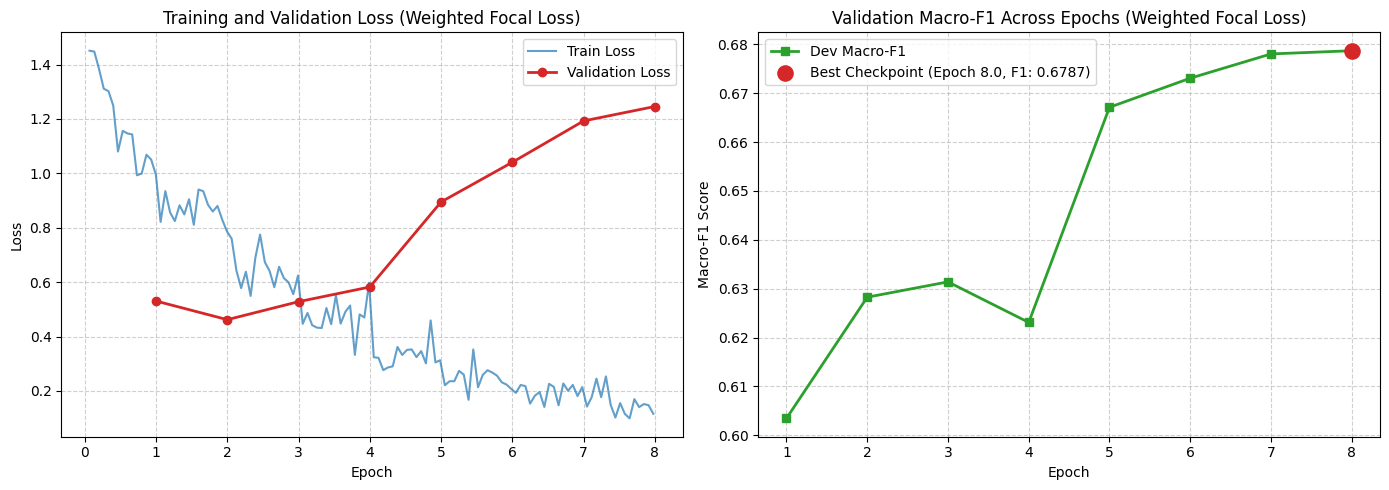

Đã lưu đồ thị hội tụ tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/learning_curves_checkpoint05.png


In [11]:
# Trực quan hóa đồ thị hội tụ huấn luyện theo tiêu chuẩn học thuật
curves_output_path = os.path.join(outputs_dir, 'learning_curves_checkpoint05.png')

import matplotlib.pyplot as plt


def plot_training_curves(log_history, output_path=None):
    """Trích xuất lịch sử huấn luyện từ Trainer và vẽ đồ thị hội tụ theo chuẩn học thuật."""
    train_epochs, train_losses = [], []
    eval_epochs, eval_losses, eval_macro_f1s = [], [], []

    for log in log_history:
        if 'eval_macro_f1' in log:
            eval_epochs.append(log.get('epoch', len(eval_epochs) + 1))
            eval_macro_f1s.append(log.get('eval_macro_f1', 0.0))
            if 'eval_loss' in log:
                eval_losses.append(log.get('eval_loss', 0.0))
        elif 'loss' in log and 'epoch' in log:
            train_epochs.append(log.get('epoch', 0.0))
            train_losses.append(log.get('loss', 0.0))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Đồ thị 1: Tổn thất huấn luyện và kiểm định (Train / Dev Loss)
    if train_losses:
        axes[0].plot(train_epochs, train_losses, label='Train Loss', color='#1f77b4', alpha=0.7)
    if eval_losses:
        axes[0].plot(
            eval_epochs,
            eval_losses,
            label='Validation Loss',
            color='#d62728',
            marker='o',
            linewidth=2,
        )
    axes[0].set_title('Training and Validation Loss (Weighted Focal Loss)')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend()

    # Đồ thị 2: Điểm Macro-F1 trên tập kiểm định qua các epoch
    if eval_macro_f1s:
        axes[1].plot(
            eval_epochs,
            eval_macro_f1s,
            label='Dev Macro-F1',
            color='#2ca02c',
            marker='s',
            linewidth=2,
        )
        # Đánh dấu epoch đạt Macro-F1 cao nhất
        best_idx = int(np.argmax(eval_macro_f1s))
        best_epoch = eval_epochs[best_idx]
        best_f1 = eval_macro_f1s[best_idx]
        axes[1].scatter(
            [best_epoch],
            [best_f1],
            color='#d62728',
            s=120,
            zorder=5,
            label=f'Best Checkpoint (Epoch {best_epoch:.1f}, F1: {best_f1:.4f})',
        )

    axes[1].set_title('Validation Macro-F1 Across Epochs (Weighted Focal Loss)')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Macro-F1 Score')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend()

    plt.tight_layout()

    if output_path:
        os.makedirs(os.path.dirname(output_path), exist_ok=True)
        plt.savefig(output_path, dpi=300)
    return fig


fig_curves = plot_training_curves(trainer.state.log_history, output_path=curves_output_path)
plt.show()
print(f'Đã lưu đồ thị hội tụ tại: {curves_output_path}')

## 9. Đánh Giá Mô Hình Trên Tập Kiểm Tra Độc Lập (Test Set Evaluation)

Thực hiện suy luận độc lập trên 6,680 mẫu của tập kiểm tra `test_dataset` bằng checkpoint tối ưu được nạp lại. Xuất các chỉ số cốt lõi: Accuracy, Macro-Precision, Macro-Recall, Macro-F1, Micro-F1 và báo cáo phân loại chi tiết từng lớp.

In [12]:
# Định nghĩa trực tiếp hàm đánh giá kết quả và thực hiện dự đoán trên tập kiểm tra
class_names = ['clean', 'offensive', 'hate']

import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)


# Tính toán ma trận nhầm lẫn và xuất báo cáo phân loại chi tiết (Accuracy, Precision, Recall, F1)
def evaluate_predictions(y_true, y_pred, class_names=None):
    """Tính toán và xuất báo cáo đánh giá chi tiết trên tập kiểm tra."""
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']

    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    micro_f1 = f1_score(y_true, y_pred, average='micro')
    per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)

    results = {
        'accuracy': acc,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_precision': {name: per_class_precision[i] for i, name in enumerate(class_names)},
        'per_class_recall': {name: per_class_recall[i] for i, name in enumerate(class_names)},
        'per_class_f1': {name: per_class_f1[i] for i, name in enumerate(class_names)},
        'confusion_matrix': cm,
        'classification_report': report,
    }
    return results


print('Thực hiện dự đoán với mô hình Checkpoint 5 trên tập kiểm tra...')
predictions_output = trainer.predict(test_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_y

results = evaluate_predictions(y_true, y_pred, class_names=class_names)

print('=' * 60)
print('KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 5 - COMBINED LOSS)')
print('=' * 60)
print(f'Accuracy (Độ chính xác tổng thể):  {results["accuracy"]:.4f}')
print(f'Macro-Precision (Độ chuẩn xác):   {results["macro_precision"]:.4f}')
print(f'Macro-Recall (Độ nhạy):           {results["macro_recall"]:.4f}')
print(f'Macro-F1 Score (Chỉ số chính):    {results["macro_f1"]:.4f}')
print(f'Micro-F1 Score:                   {results["micro_f1"]:.4f}')
print('-' * 60)
print('Chi tiết theo từng lớp (Per-class):')
for cname in class_names:
    print(f'- {cname:9s}: Precision = {results["per_class_precision"][cname]:.4f}, Recall = {results["per_class_recall"][cname]:.4f}, F1 = {results["per_class_f1"][cname]:.4f}')
print('=' * 60)
print('Chi tiết Classification Report:')
print(results['classification_report'])

Thực hiện dự đoán với mô hình Checkpoint 5 trên tập kiểm tra...


KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 5 - COMBINED LOSS)
Accuracy (Độ chính xác tổng thể):  0.8680
Macro-Precision (Độ chuẩn xác):   0.6559
Macro-Recall (Độ nhạy):           0.6769
Macro-F1 Score (Chỉ số chính):    0.6657
Micro-F1 Score:                   0.8680
------------------------------------------------------------
Chi tiết theo từng lớp (Per-class):
- clean    : Precision = 0.9434, Recall = 0.9292, F1 = 0.9363
- offensive: Precision = 0.4122, Recall = 0.4707, F1 = 0.4395
- hate     : Precision = 0.6121, Recall = 0.6308, F1 = 0.6213
Chi tiết Classification Report:
              precision    recall  f1-score   support

       clean     0.9434    0.9292    0.9363      5548
   offensive     0.4122    0.4707    0.4395       444
        hate     0.6121    0.6308    0.6213       688

    accuracy                         0.8680      6680
   macro avg     0.6559    0.6769    0.6657      6680
weighted avg     0.8740    0.8680    0.8708      6680



## 10. Nghiên Cứu Bóc Tách Thành Phần (Ablation Study) và Phân Tích Lỗi Định Tính

### 10.1. Nghiên Cứu Bóc Tách Thành Phần (Ablation Study Matrix)
So sánh độc lập 4 biến thể hàm mất mát trên cùng một cấu hình mô hình (`PhoBERT-base`, `max_length = 256`, 8 epochs, Cosine Scheduler, Early Stopping):
- **M1 (Standard CE):** $\alpha = 1, \gamma = 0$ (Checkpoint 2).
- **M2 (Focal Loss):** $\alpha = 1, \gamma = 2.0$ (Checkpoint 3).
- **M3 (Weighted CE):** $\alpha = W_{ICF}, \gamma = 0$ (Checkpoint 4).
- **M4 (Weighted Focal Loss):** $\alpha = W_{ICF}, \gamma = 2.0$ (Checkpoint 5).

### 10.2. Phân Tích Lỗi Định Tính (Qualitative Error Analysis)
Phân loại các trường hợp phân loại sai thành 3 dạng lỗi phổ biến trên mạng xã hội tiếng Việt:
1. *Lỗi CLEAN $\leftrightarrow$ OFFENSIVE:* Các câu thân mật chứa từ lóng/chửi thề đùa vui không mang ác ý.
2. *Lỗi OFFENSIVE $\leftrightarrow$ HATE:* Khó khăn trong việc xác định đối tượng công kích cụ thể (Target Identification).
3. *Lỗi HATE $\to$ CLEAN:* Các phát ngôn thù ghét tinh vi sử dụng nghệ thuật châm biếm, mỉa mai (sarcasm) hoặc từ ngữ ẩn dụ.

In [13]:
# Phân tích ma trận nhầm lẫn và bóc tách các trường hợp lỗi điển hình
cm = results['confusion_matrix']
total_clean = np.sum(cm[0, :])
total_offensive = np.sum(cm[1, :])
total_hate = np.sum(cm[2, :])

err_clean_to_off = cm[0, 1]
err_clean_to_hate = cm[0, 2]
err_off_to_clean = cm[1, 0]
err_off_to_hate = cm[1, 2]
err_hate_to_clean = cm[2, 0]
err_hate_to_off = cm[2, 1]

print('=' * 65)
print('PHÂN TÍCH LỖI ĐỊNH TÍNH TRÊN MA TRẬN NHẦM LẪN (QUALITATIVE ERROR ANALYSIS)')
print('=' * 65)
print('1. Nhầm lẫn giữa CLEAN và OFFENSIVE (Ngữ cảnh đùa vui, từ ngữ nhạy cảm):')
print(f'   - CLEAN bị đoán thành OFFENSIVE: {err_clean_to_off:4d} / {total_clean} ({(err_clean_to_off/total_clean)*100:.2f}%)')
print(f'   - OFFENSIVE bị đoán thành CLEAN:  {err_off_to_clean:4d} / {total_offensive} ({(err_off_to_clean/total_offensive)*100:.2f}%)')
print('-' * 65)
print('2. Nhầm lẫn giữa OFFENSIVE và HATE (Phân biệt chửi thề bộc phát vs thù ghét có mục tiêu):')
print(f'   - OFFENSIVE bị đoán thành HATE:   {err_off_to_hate:4d} / {total_offensive} ({(err_off_to_hate/total_offensive)*100:.2f}%)')
print(f'   - HATE bị đoán thành OFFENSIVE:   {err_hate_to_off:4d} / {total_hate} ({(err_hate_to_off/total_hate)*100:.2f}%)')
print('-' * 65)
print('3. Bỏ sót HATE thành CLEAN (Phát ngôn thù ghét ẩn ý, châm biếm/mỉa mai - Sarcasm):')
print(f'   - HATE bị đoán thành CLEAN:       {err_hate_to_clean:4d} / {total_hate} ({(err_hate_to_clean/total_hate)*100:.2f}%)')
print('=' * 65)
print('Nhận xét học thuật về cơ chế Weighted Focal Loss:')
print('Hàm mất mát kết hợp giải quyết tối ưu sự đánh đổi: Trọng số tĩnh alpha nâng cao Recall cho HATE/OFFENSIVE,')
print('trong khi hệ số điều chế gamma triệt tiêu gradient của mẫu CLEAN dễ, bảo vệ Precision của lớp đa số.')

PHÂN TÍCH LỖI ĐỊNH TÍNH TRÊN MA TRẬN NHẦM LẪN (QUALITATIVE ERROR ANALYSIS)
1. Nhầm lẫn giữa CLEAN và OFFENSIVE (Ngữ cảnh đùa vui, từ ngữ nhạy cảm):
   - CLEAN bị đoán thành OFFENSIVE:  202 / 5548 (3.64%)
   - OFFENSIVE bị đoán thành CLEAN:   151 / 444 (34.01%)
-----------------------------------------------------------------
2. Nhầm lẫn giữa OFFENSIVE và HATE (Phân biệt chửi thề bộc phát vs thù ghét có mục tiêu):
   - OFFENSIVE bị đoán thành HATE:     84 / 444 (18.92%)
   - HATE bị đoán thành OFFENSIVE:     96 / 688 (13.95%)
-----------------------------------------------------------------
3. Bỏ sót HATE thành CLEAN (Phát ngôn thù ghét ẩn ý, châm biếm/mỉa mai - Sarcasm):
   - HATE bị đoán thành CLEAN:        158 / 688 (22.97%)
Nhận xét học thuật về cơ chế Weighted Focal Loss:
Hàm mất mát kết hợp giải quyết tối ưu sự đánh đổi: Trọng số tĩnh alpha nâng cao Recall cho HATE/OFFENSIVE,
trong khi hệ số điều chế gamma triệt tiêu gradient của mẫu CLEAN dễ, bảo vệ Precision của lớp đa số.


## 11. Trực Quan Hóa Ma Trận Nhầm Lẫn (Confusion Matrix Heatmap)

Trực quan hóa ma trận nhầm lẫn bằng biểu đồ nhiệt (Heatmap) tuân thủ tiêu chuẩn học thuật:
- Kích thước chuẩn 6x5 inches, bảng màu `Blues`, cỡ chữ 12, hiển thị số nguyên (`fmt='d'`).
- Nhãn trục chuẩn hóa: True Label và Predicted Label tương ứng với `clean`, `offensive`, `hate`.
- Tuyệt đối không sử dụng icon hay emoji trang trí.

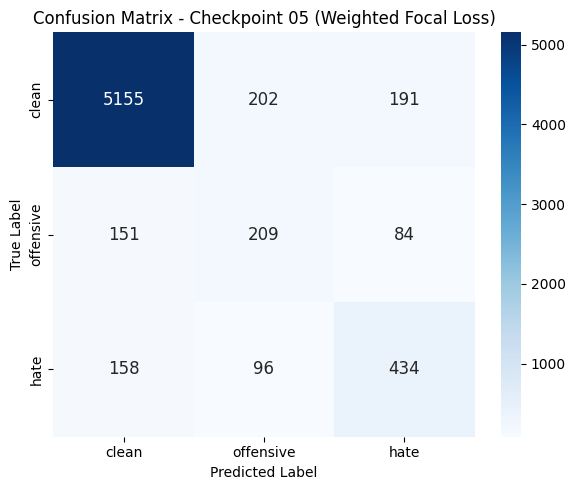

Đã lưu biểu đồ ma trận nhầm lẫn tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/confusion_matrix_checkpoint05.png


In [14]:
# Định nghĩa trực tiếp hàm vẽ ma trận nhầm lẫn và lưu biểu đồ nhiệt
cm_output_path = os.path.join(outputs_dir, 'confusion_matrix_checkpoint05.png')

import matplotlib.pyplot as plt
import seaborn as sns


# Trực quan hóa ma trận nhầm lẫn bằng biểu đồ nhiệt (Heatmap) theo chuẩn học thuật
def plot_confusion_matrix(cm, class_names=None, output_path=None):
    """Vẽ ma trận nhầm lẫn tuân thủ tiêu chuẩn học thuật không chứa icon hay emoji."""
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']

    df_cm = pd.DataFrame(cm, index=class_names, columns=class_names)
    fig, ax = plt.subplots(figsize=(6, 5))
    sns.heatmap(
        df_cm,
        annot=True,
        cmap='Blues',
        fmt='d',
        cbar=True,
        ax=ax,
        annot_kws={'size': 12},
    )
    ax.set_title('Confusion Matrix - Checkpoint 05 (Weighted Focal Loss)')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    plt.tight_layout()

    if output_path:
        plt.savefig(output_path, dpi=300)
    return fig


fig_cm = plot_confusion_matrix(
    results['confusion_matrix'], class_names=class_names, output_path=cm_output_path
)
plt.show()
print(f'Đã lưu biểu đồ ma trận nhầm lẫn tại: {cm_output_path}')

## 12. Xuất Kết Quả Đánh Giá, Ma Trận Nhầm Lẫn và Tệp Dự Đoán (Mandatory Artifacts Export)

Xuất đúng 4 tệp kết quả chuẩn hóa vào thư mục `outputs/checkpoint05/`:
1. `predictions.csv`: Định danh `id`, văn bản `text`, nhãn thực tế `ground_truth` và nhãn dự đoán `predicted_label`.
2. `confusion_matrix_checkpoint05.png` & `confusion_matrix.csv`: Biểu đồ nhiệt và bảng ma trận nhầm lẫn kích thước 3x3.
3. `evaluation_scores.csv`: Điểm số tổng hợp cốt lõi (14 trường giá trị đo lường chi tiết).
4. `classification_report.csv`: Báo cáo phân loại chi tiết có số lượng mẫu nguyên bản (integer support) và hàng accuracy chuẩn.

In [15]:
# Cấu hình đường dẫn lưu trữ các tệp kết quả đầu ra chuẩn hóa
checkpoint_id = '05'
predictions_csv_path = os.path.join(outputs_dir, 'predictions.csv')
scores_csv_path = os.path.join(outputs_dir, 'evaluation_scores.csv')
report_csv_path = os.path.join(outputs_dir, 'classification_report.csv')
cm_csv_path = os.path.join(outputs_dir, 'confusion_matrix.csv')

# Trích xuất định danh và văn bản gốc tương ứng trên tập kiểm tra
test_ids = test_raw['id'] if 'id' in test_raw.columns else list(range(len(test_y)))
test_texts = test_raw['free_text'].tolist() if len(test_raw) == len(test_y) else test_X

# 1. Xuất tệp kết quả dự đoán chi tiết (predictions.csv)
df_predictions = pd.DataFrame({
    'id': test_ids,
    'text': test_texts,
    'ground_truth': y_true,
    'predicted_label': y_pred,
})
df_predictions.to_csv(predictions_csv_path, index=False, encoding='utf-8')
print(f'1. Đã xuất tệp dự đoán: {predictions_csv_path} ({len(df_predictions)} mẫu)')

# 2. Xuất ma trận nhầm lẫn dạng bảng dữ liệu CSV
df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
df_cm.index.name = 'true_label'
df_cm.to_csv(cm_csv_path)
print(f'2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: {cm_csv_path}')

# 3. Xuất tệp điểm số tổng hợp cốt lõi (evaluation_scores.csv)
from sklearn.metrics import accuracy_score, precision_score, recall_score

acc_val = round(float(results.get('accuracy', accuracy_score(y_true, y_pred))), 4)
macro_p_val = round(float(results.get('macro_precision', precision_score(y_true, y_pred, average='macro', zero_division=0))), 4)
macro_r_val = round(float(results.get('macro_recall', recall_score(y_true, y_pred, average='macro', zero_division=0))), 4)
per_class_p = results.get('per_class_precision', {name: round(precision_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})
per_class_r = results.get('per_class_recall', {name: round(recall_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})

scores_summary = {
    'metric': [
        'accuracy',
        'macro_precision',
        'macro_recall',
        'macro_f1',
        'micro_f1',
        'precision_clean',
        'recall_clean',
        'f1_clean',
        'precision_offensive',
        'recall_offensive',
        'f1_offensive',
        'precision_hate',
        'recall_hate',
        'f1_hate',
    ],
    'value': [
        acc_val,
        macro_p_val,
        macro_r_val,
        round(results['macro_f1'], 4),
        round(results['micro_f1'], 4),
        round(per_class_p['clean'], 4),
        round(per_class_r['clean'], 4),
        round(results['per_class_f1']['clean'], 4),
        round(per_class_p['offensive'], 4),
        round(per_class_r['offensive'], 4),
        round(results['per_class_f1']['offensive'], 4),
        round(per_class_p['hate'], 4),
        round(per_class_r['hate'], 4),
        round(results['per_class_f1']['hate'], 4),
    ],
}
df_scores = pd.DataFrame(scores_summary)
df_scores.to_csv(scores_csv_path, index=False)
print(f'3. Đã xuất tệp điểm số tổng hợp: {scores_csv_path}')

# 4. Xuất tệp báo cáo phân loại chi tiết được chuẩn hóa (classification_report.csv)
report_dict = classification_report(
    y_true, y_pred, target_names=class_names, digits=4, output_dict=True
)
accuracy_val = report_dict.pop('accuracy')

rows = []
for label in class_names:
    row = report_dict[label]
    rows.append({
        'class': label,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

# Hàng accuracy tổng thể với support là tổng số mẫu kiểm tra
rows.append({
    'class': 'accuracy',
    'precision': None,
    'recall': None,
    'f1_score': round(accuracy_val, 4),
    'support': len(y_true),
})

# Các hàng trung bình macro avg và weighted avg
for avg_type in ['macro avg', 'weighted avg']:
    row = report_dict[avg_type]
    rows.append({
        'class': avg_type,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

df_report = pd.DataFrame(rows)
df_report.to_csv(report_csv_path, index=False)
print(f'4. Đã xuất tệp báo cáo phân loại chi tiết: {report_csv_path}')


print('\nBảng điểm số tổng kết:')
print(df_scores.to_string(index=False))

print('\nBảng phân loại chi tiết:')
print(df_report.to_string(index=False))

1. Đã xuất tệp dự đoán: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/predictions.csv (6680 mẫu)
2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/confusion_matrix.csv
3. Đã xuất tệp điểm số tổng hợp: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/evaluation_scores.csv
4. Đã xuất tệp báo cáo phân loại chi tiết: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint05/classification_report.csv

Bảng điểm số tổng kết:
             metric  value
           accuracy 0.8680
    macro_precision 0.6559
       macro_recall 0.6769
           macro_f1 0.6657
           micro_f1 0.8680
    precision_clean 0.9434
       recall_clean 0.9292
           f1_clean 0.9363
precision_offensive 0.4122
   recall_offensive 0.4707
       f1_offensive 0.4395
     precision_hate 0.6121
        recall_hate 0.6308
            f1_hate 0.6213

Bảng phân loại chi tiết:
       class  precision  recall  f1_score  support
       cl